# SRCNN x3: 3-layer variants vs 4-layer 

## 1. Download data and checkpoints

In [1]:
import kagglehub

kagglehub.dataset_download("jesucristo/super-resolution-benchmarks")
for v in ["three_layer_baseline/5", "three_layer_sharp/5", "three_layer_smooth/5", "four_layer/5"]:
    print(kagglehub.model_download(f"amiraliabedi97/srcnn3/pyTorch/{v}"))


/kaggle/input/models/amiraliabedi97/srcnn3/pytorch/three_layer_baseline/5
/kaggle/input/models/amiraliabedi97/srcnn3/pytorch/three_layer_sharp/5
/kaggle/input/models/amiraliabedi97/srcnn3/pytorch/three_layer_smooth/5
/kaggle/input/models/amiraliabedi97/srcnn3/pytorch/four_layer/5


## 2. Paths

In [2]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision.transforms import functional as TF

image_dir  = '/kaggle/input/datasets/jesucristo/super-resolution-benchmarks/Set14/Set14/original'
model_path = '/kaggle/input/models/amiraliabedi97/srcnn3/pytorch/'
scale = 3

print(sorted(os.listdir(image_dir)))
print(sorted(os.listdir(model_path)))


['baboon.png', 'barbara.png', 'bridge.png', 'coastguard.png', 'comic.png', 'face.png', 'flowers.png', 'foreman.png', 'lenna.png', 'man.png', 'monarch.png', 'pepper.png', 'ppt3.png', 'zebra.png']
['four_layer', 'three_layer_baseline', 'three_layer_sharp', 'three_layer_smooth']


## 3. Model architectures
| Variant | Kernels | Params | Receptive field |
|---|---|---|---|
| four_layer | 9-3-1-5 | ~7.9k | 15x15 |
| baseline | 9-1-5 | ~8.1k | 13x13 |
| sharp | 7-3-3 | ~22.0k | 11x11 |
| smooth | 11-1-7 | ~11.5k | 17x17 |



In [3]:
class four_layer_SRCNN(nn.Module):          # 9-3-1-5
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 9, padding=4), nn.ReLU(inplace=True),
            nn.Conv2d(32, 16, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(16, 16, 1), nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, 5, padding=2))
    def forward(self, x): return self.net(x)

class three_layer_baseline_SRCNN(nn.Module):  # 9-1-5
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 9, padding=4), nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, 1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 5, padding=2))
    def forward(self, x): return self.net(x)

class three_layer_smooth_SRCNN(nn.Module):    # 11-1-7
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 11, padding=5), nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, 1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 7, padding=3))
    def forward(self, x): return self.net(x)

class three_layer_sharp_SRCNN(nn.Module):     # 7-3-3
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 7, padding=3), nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 3, padding=1))
    def forward(self, x): return self.net(x)

# sanity check: parameter counts
for cls in [four_layer_SRCNN, three_layer_baseline_SRCNN, three_layer_smooth_SRCNN, three_layer_sharp_SRCNN]:
    print(f"{cls.__name__:<28} {sum(p.numel() for p in cls().parameters()):>7,} params")


four_layer_SRCNN               7,921 params
three_layer_baseline_SRCNN     8,129 params
three_layer_smooth_SRCNN      11,457 params
three_layer_sharp_SRCNN       21,953 params


## 4. Metrics and evaluation helpers

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def _to_4d(x):
    """PIL / 2D / 3D tensor -> float tensor [1,1,H,W] in [0,1]."""
    if not torch.is_tensor(x):
        x = TF.to_tensor(x)
    x = x.float()
    if x.dim() == 2:
        x = x[None, None]
    elif x.dim() == 3:
        x = x[None]
    return x


def _quantize8(x):
    """Simulate saving as 8-bit image, with rounding."""
    return torch.round(torch.clamp(x, 0, 1) * 255.0) / 255.0


def _shave(x, s):
    return x[..., s:-s, s:-s] if s > 0 else x


def compute_psnr(ref, test, shave_border=3):
    ref, test = _to_4d(ref), _quantize8(_to_4d(test))
    ref, test = _shave(ref, shave_border), _shave(test, shave_border)
    mse = torch.mean((ref - test) ** 2).item()
    return float("inf") if mse == 0 else 10.0 * math.log10(1.0 / mse)


def _gaussian_window(size=11, sigma=1.5):
    coords = torch.arange(size).float() - size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] * g[None, :])[None, None]  # [1,1,size,size]


def compute_ssim(ref, test, shave_border=3, C1=0.01 ** 2, C2=0.03 ** 2):
    ref, test = _to_4d(ref), _quantize8(_to_4d(test))
    ref, test = _shave(ref, shave_border), _shave(test, shave_border)
    w = _gaussian_window().to(ref.device)

    def blur(t):
        return F.conv2d(t, w)  # 'valid' conv -> no border bias

    mu1, mu2 = blur(ref), blur(test)
    mu1_sq, mu2_sq, mu12 = mu1 * mu1, mu2 * mu2, mu1 * mu2
    s1 = blur(ref * ref) - mu1_sq
    s2 = blur(test * test) - mu2_sq
    s12 = blur(ref * test) - mu12
    ssim_map = ((2 * mu12 + C1) * (2 * s12 + C2)) / ((mu1_sq + mu2_sq + C1) * (s1 + s2 + C2))
    return ssim_map.mean().item()


In [5]:
MODEL_SPECS = {  # name -> (class, folder in model_path)
    "Smooth (11-1-7)":   ("three_layer_smooth_SRCNN",   "three_layer_smooth"),
    "Baseline (9-1-5)":  ("three_layer_baseline_SRCNN", "three_layer_baseline"),
    "Sharp (7-3-3)":     ("three_layer_sharp_SRCNN",    "three_layer_sharp"),
    "Four-layer (9-3-1-5)": ("four_layer_SRCNN",        "four_layer"),
}
BASELINE_NAME = "Baseline (9-1-5)"


def load_models(model_path, dataset):
    models = {}
    for name, (cls_name, folder) in MODEL_SPECS.items():
        model = globals()[cls_name]()
        weights = os.path.join(model_path, folder, "5", f"{dataset}.pth")
        sd = torch.load(weights, map_location=DEVICE)
        sd = {k.replace("module.", "", 1): v for k, v in sd.items()}
        model.load_state_dict(sd)
        models[name] = model.to(DEVICE).eval()
    return models

def crop_to_scale(img, scale):
    w, h = img.size
    return img.crop((0, 0, (w // scale) * scale, (h // scale) * scale))


def evaluate_image(image, models, scale=3):
    """Returns (results, outputs).
    results: {name: (psnr, ssim)}, including 'Bicubic'.
    outputs: {name: RGB PIL image} for plotting.
    """
    image = crop_to_scale(image.convert("RGB"), scale)
    w, h = image.size
    lr_size = (w // scale, h // scale)

    y_gt, cb, cr = image.convert("YCbCr").split()
    y_up = y_gt.resize(lr_size, Image.BICUBIC).resize((w, h), Image.BICUBIC)
    cb_up = cb.resize(lr_size, Image.BICUBIC).resize((w, h), Image.BICUBIC)
    cr_up = cr.resize(lr_size, Image.BICUBIC).resize((w, h), Image.BICUBIC)

    gt = TF.to_tensor(y_gt)[None]            # [1,1,H,W], values k/255
    bic = TF.to_tensor(y_up)[None]

    def to_rgb(y_tensor):
        y_pil = TF.to_pil_image(_quantize8(y_tensor).squeeze(0))
        return Image.merge("YCbCr", (y_pil, cb_up, cr_up)).convert("RGB")

    results = {"Bicubic": (compute_psnr(gt, bic, scale), compute_ssim(gt, bic, scale))}
    outputs = {"Bicubic": to_rgb(bic)}

    with torch.no_grad():
        for name, model in models.items():
            out = torch.clamp(model(bic.to(DEVICE)).cpu(), 0, 1)   # float output
            results[name] = (compute_psnr(gt, out, scale), compute_ssim(gt, out, scale))
            outputs[name] = to_rgb(out)
    return results, outputs


def run_benchmark(image_dir, model_path, dataset="general100", scale=3, verbose=True):
    models = load_models(model_path, dataset)
    files = sorted(f for f in os.listdir(image_dir) if f.lower().endswith((".png", ".jpg", ".bmp")))
    per_image = {}  # name -> list of (psnr, ssim)

    for f in files:
        res, _ = evaluate_image(Image.open(os.path.join(image_dir, f)), models, scale)
        for name, v in res.items():
            per_image.setdefault(name, []).append(v)
        if verbose:
            line = " | ".join(f"{n.split(' ')[0]} {v[0]:.3f}" for n, v in res.items())
            print(f"{f[:-4]:<10} {line}")

    names = list(per_image.keys())
    psnr = {n: np.array([v[0] for v in per_image[n]]) for n in names}
    ssim = {n: np.array([v[1] for v in per_image[n]]) for n in names}

    print(f"\n=== Average over {len(files)} images | trained on {dataset} | x{scale} | Y channel ===")
    print(f"{'Model':<24}{'PSNR':>9}{'SSIM':>9}")
    for n in names:
        extra = ""
        print(f"{n:<24}{psnr[n].mean():9.3f}{ssim[n].mean():9.4f}{extra}")
    return psnr, ssim


## 5. Benchmark on Set14 (x3)

In [6]:
dataset = 'urban100'     # one of: t91, urban100, manga109, bsds500, general100
psnr, ssim = run_benchmark(image_dir, model_path, dataset=dataset, scale=scale)


baboon     Bicubic 21.884 | Smooth 22.260 | Baseline 22.251 | Sharp 22.247 | Four-layer 22.255
barbara    Bicubic 24.930 | Smooth 25.427 | Baseline 25.409 | Sharp 25.359 | Four-layer 25.337
bridge     Bicubic 24.400 | Smooth 24.989 | Baseline 24.974 | Sharp 24.980 | Four-layer 24.958
coastguard Bicubic 25.221 | Smooth 25.823 | Baseline 25.787 | Sharp 25.781 | Four-layer 25.793
comic      Bicubic 21.791 | Smooth 22.916 | Baseline 22.851 | Sharp 22.917 | Four-layer 22.863
face       Bicubic 31.523 | Smooth 32.160 | Baseline 32.086 | Sharp 32.129 | Four-layer 32.140
flowers    Bicubic 25.903 | Smooth 27.358 | Baseline 27.273 | Sharp 27.371 | Four-layer 27.307
foreman    Bicubic 29.789 | Smooth 31.934 | Baseline 31.926 | Sharp 32.081 | Four-layer 32.039
lenna      Bicubic 30.351 | Smooth 31.819 | Baseline 31.778 | Sharp 31.808 | Four-layer 31.828
man        Bicubic 25.684 | Smooth 26.701 | Baseline 26.652 | Sharp 26.696 | Four-layer 26.707
monarch    Bicubic 28.104 | Smooth 30.497 | Baseli

In [7]:
for ds in ['t91', 'urban100', 'manga109', 'bsds500', 'general100']:
    try:
        run_benchmark(image_dir, model_path, dataset=ds, scale=scale, verbose=False)
    except FileNotFoundError as e:
        print(f"[skip] {ds}: {e}")



=== Average over 14 images | trained on t91 | x3 | Y channel ===
Model                        PSNR     SSIM
Bicubic                    26.306   0.7561
Smooth (11-1-7)            27.010   0.7786
Baseline (9-1-5)           26.832   0.7734
Sharp (7-3-3)              26.917   0.7775
Four-layer (9-3-1-5)       26.741   0.7722

=== Average over 14 images | trained on urban100 | x3 | Y channel ===
Model                        PSNR     SSIM
Bicubic                    26.306   0.7561
Smooth (11-1-7)            27.595   0.7934
Baseline (9-1-5)           27.545   0.7914
Sharp (7-3-3)              27.603   0.7916
Four-layer (9-3-1-5)       27.572   0.7912

=== Average over 14 images | trained on manga109 | x3 | Y channel ===
Model                        PSNR     SSIM
Bicubic                    26.306   0.7561
Smooth (11-1-7)            27.559   0.7888
Baseline (9-1-5)           27.471   0.7878
Sharp (7-3-3)              27.524   0.7864
Four-layer (9-3-1-5)       27.521   0.7876

=== Average over 

## 6. Visual comparison

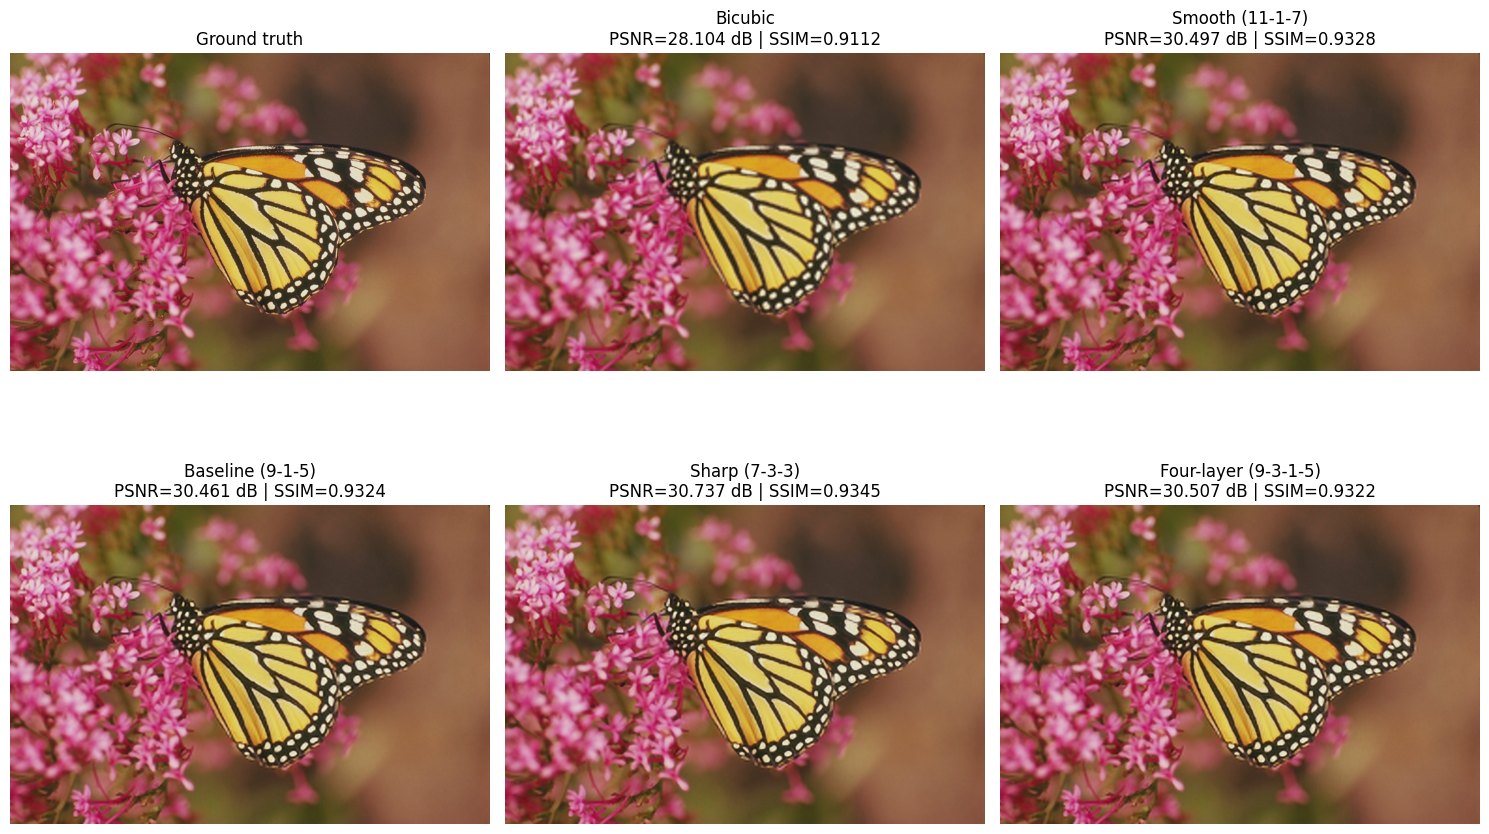

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

name = 'monarch.png'
crop = None          

models = load_models(model_path, dataset)
full = crop_to_scale(Image.open(os.path.join(image_dir, name)).convert('RGB'), scale)
img = full.crop((crop[0], crop[1], crop[0] + crop[2], crop[1] + crop[3])) if crop else full
img = crop_to_scale(img, scale)

res, outs = evaluate_image(img, models, scale)

panels = [('Ground truth', img)] + [(n, outs[n]) for n in outs]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (title, im) in zip(axes.flat, panels):
    ax.imshow(im)
    if title in res:
        ax.set_title(f"{title}\nPSNR={res[title][0]:.3f} dB | SSIM={res[title][1]:.4f}")
    else:
        ax.set_title(title)
    ax.axis('off')
plt.tight_layout(); plt.show()


## 7. Zoomed patch comparison
Models run on the **full** image; then the same patch is cut from every output. Edit `patch_x/patch_y/patch_w/patch_h` (pixels in the full image) and `psnr_mode` (`'patch'` or `'full'`).

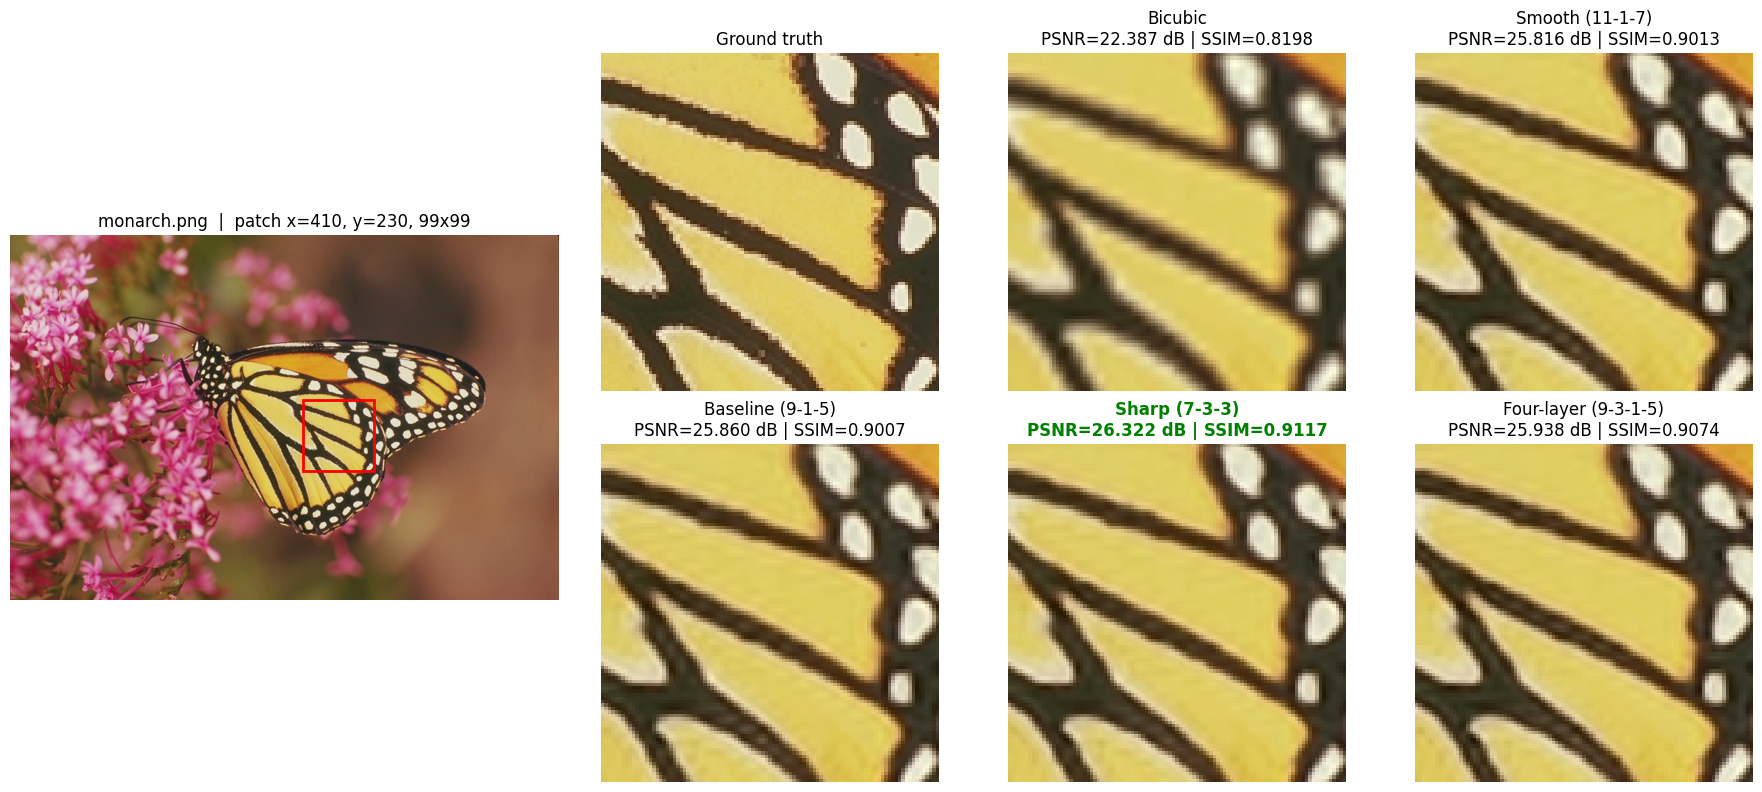

In [9]:
name      = 'monarch.png'

patch_x   = 410         
patch_y   = 230          
patch_w   = 99           
patch_h   = 99   

psnr_mode = 'patch'

models = load_models(model_path, dataset)
full = crop_to_scale(Image.open(os.path.join(image_dir, name)).convert('RGB'), scale)
W, H = full.size

# keep the patch inside the image
patch_w = min(patch_w, W); patch_h = min(patch_h, H)
px = max(0, min(patch_x, W - patch_w))
py = max(0, min(patch_y, H - patch_h))
box = (px, py, px + patch_w, py + patch_h)
if (px, py) != (patch_x, patch_y):
    print(f"[note] patch moved to x={px}, y={py} to stay inside the image ({W}x{H})")

res, outs = evaluate_image(full, models, scale)
panels = [('Ground truth', full)] + [(n, outs[n]) for n in outs]

def y_patch(im):
    return TF.to_tensor(im.convert('YCbCr').split()[0].crop(box))[None]

gt_patch = y_patch(full)
scores, ssims = {}, {}
for n in outs:
    if psnr_mode == 'patch':
        scores[n] = compute_psnr(gt_patch, y_patch(outs[n]), shave_border=0)
        ssims[n]  = compute_ssim(gt_patch, y_patch(outs[n]), shave_border=0)
    else:
        scores[n], ssims[n] = res[n]          # (psnr, ssim) of the whole image
best = max(scores, key=scores.get)

fig = plt.figure(figsize=(18, 8))
gs = GridSpec(2, 4, width_ratios=[1.4, 1, 1, 1], figure=fig)

ax0 = fig.add_subplot(gs[:, 0])
ax0.imshow(full)
ax0.add_patch(patches.Rectangle((px, py), patch_w, patch_h, fill=False, edgecolor='red', linewidth=2))
ax0.set_title(f"{name}  |  patch x={px}, y={py}, {patch_w}x{patch_h}")
ax0.axis('off')

for i, (title, im) in enumerate(panels):
    ax = fig.add_subplot(gs[i // 3, 1 + i % 3])
    ax.imshow(im.crop(box), interpolation='nearest')
    im.crop(box).save(f'{title}.png')
    if title in scores:
        ax.set_title(f"{title}\nPSNR={scores[title]:.3f} dB | SSIM={ssims[title]:.4f}",
                     color='green' if title == best else 'black',
                     fontweight='bold' if title == best else 'normal')
    else:
        ax.set_title(title)
    ax.axis('off')

plt.tight_layout(); plt.show()

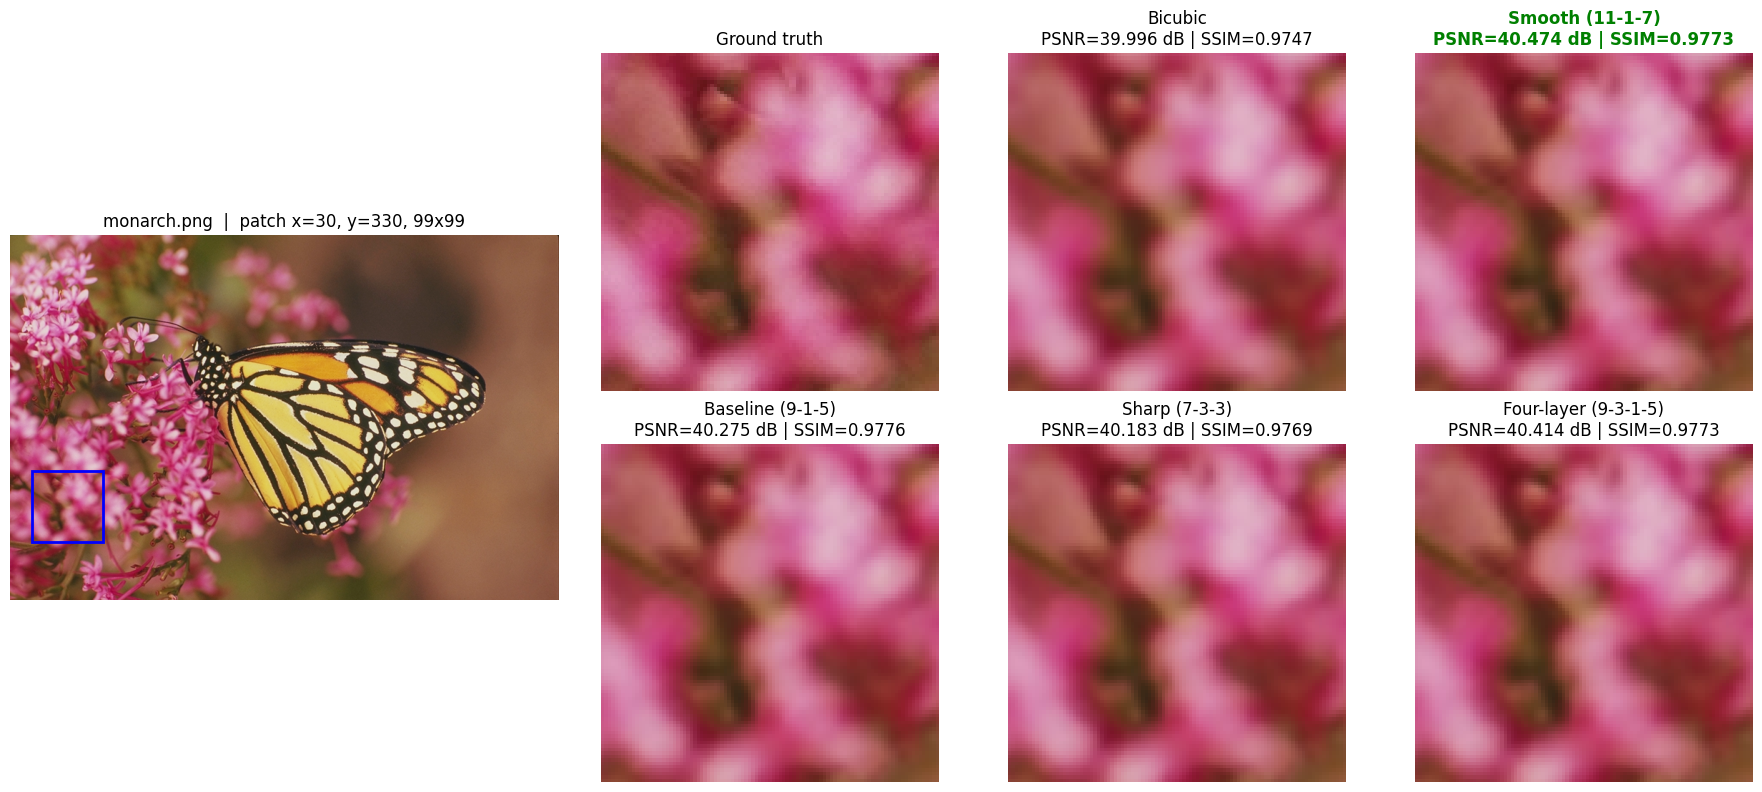

In [10]:
patch_x   = 30          
patch_y   = 330          
patch_w   = 99           
patch_h   = 99

models = load_models(model_path, dataset)
full = crop_to_scale(Image.open(os.path.join(image_dir, name)).convert('RGB'), scale)
W, H = full.size

patch_w = min(patch_w, W); patch_h = min(patch_h, H)
px = max(0, min(patch_x, W - patch_w))
py = max(0, min(patch_y, H - patch_h))
box = (px, py, px + patch_w, py + patch_h)
if (px, py) != (patch_x, patch_y):
    print(f"[note] patch moved to x={px}, y={py} to stay inside the image ({W}x{H})")

res, outs = evaluate_image(full, models, scale)
panels = [('Ground truth', full)] + [(n, outs[n]) for n in outs]

def y_patch(im):
    return TF.to_tensor(im.convert('YCbCr').split()[0].crop(box))[None]

gt_patch = y_patch(full)
scores, ssims = {}, {}
for n in outs:
    if psnr_mode == 'patch':
        scores[n] = compute_psnr(gt_patch, y_patch(outs[n]), shave_border=0)
        ssims[n]  = compute_ssim(gt_patch, y_patch(outs[n]), shave_border=0)
    else:
        scores[n], ssims[n] = res[n]          # (psnr, ssim) of the whole image
best = max(scores, key=scores.get)

fig = plt.figure(figsize=(18, 8))
gs = GridSpec(2, 4, width_ratios=[1.4, 1, 1, 1], figure=fig)

ax0 = fig.add_subplot(gs[:, 0])
ax0.imshow(full)
ax0.add_patch(patches.Rectangle((px, py), patch_w, patch_h, fill=False, edgecolor='blue', linewidth=2))
ax0.set_title(f"{name}  |  patch x={px}, y={py}, {patch_w}x{patch_h}")
ax0.axis('off')

for i, (title, im) in enumerate(panels):
    ax = fig.add_subplot(gs[i // 3, 1 + i % 3])
    ax.imshow(im.crop(box), interpolation='nearest')
    im.crop(box).save(f'{title}.png')
    if title in scores:
        ax.set_title(f"{title}\nPSNR={scores[title]:.3f} dB | SSIM={ssims[title]:.4f}",
                     color='green' if title == best else 'black',
                     fontweight='bold' if title == best else 'normal')
    else:
        ax.set_title(title)
    ax.axis('off')

plt.tight_layout(); plt.show()